# Evidencia clase 29/10/26 — Filtro pasabanda para ECG

Hasta ahora diseñamos un pasabajos, que limpia el ruido de alta frecuencia pero deja pasar el **movimiento de línea de base** (baja frecuencia, respiración y movimiento del paciente). Para sacar las dos cosas a la vez se diseña un **pasabanda**:

| Banda | Frecuencias | Requisito |
|---|---|---|
| Rechazo inferior | $0$ a $w_{s1} = 0.1$ Hz | $\leq -40$ dB |
| Transición inferior | $0.1$ a $1$ Hz | libre |
| Paso | $w_{p1} = 1$ a $w_{p2} = 35$ Hz | $\geq -3$ dB |
| Transición superior | $35$ a $50$ Hz | libre |
| Rechazo superior | desde $w_{s2} = 50$ Hz | $\leq -40$ dB |

La dificultad está en el borde inferior: la transición mide apenas **0.9 Hz** con $f_s = 1000$ Hz, o sea $0.0018\,\pi$ rad/muestra. Esa transición tan angosta es la que define el orden de los filtros, sobre todo de los FIR.

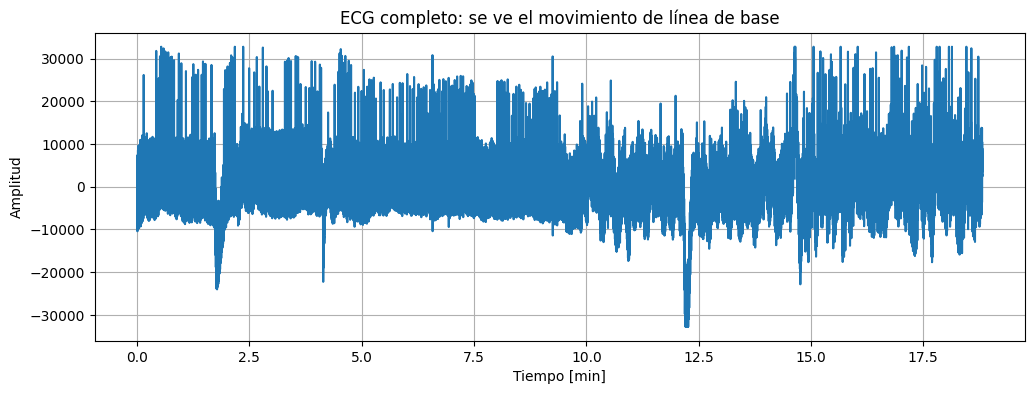

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from matplotlib.patches import Rectangle

fs_ecg = 1000 # Hz

mat_struct = sio.loadmat('../Extra/TS5/ECG_TP4.mat')
ecg_one_lead = mat_struct['ecg_lead'].flatten() * 1.0
N = len(ecg_one_lead)

plt.figure(figsize=(12, 4))
plt.plot(np.arange(N) / fs_ecg / 60, ecg_one_lead)
plt.xlabel('Tiempo [min]')
plt.ylabel('Amplitud')
plt.title('ECG completo: se ve el movimiento de línea de base')
plt.grid(True)
plt.show()

## Diseño de los filtros IIR

Con `iirdesign`, para un pasabanda `wp` y `ws` pasan a ser **listas** con los dos bordes: `[wp1, wp2]` y `[ws1, ws2]`. Igual que antes, se predistorsiona la plantilla ($G_{pass}/2$, $G_{stop}/2$) porque se va a filtrar con `sosfiltfilt`.

In [2]:
ws1 = .1  #[Hz]
wp1 = 1.0 #[Hz]
wp2 = 35  #[Hz]
ws2 = 50  #[Hz]

Gpass = 3
Gstop = 40
ripple = Gpass
att = Gstop

# predist por filt filt
sos_butt = sig.iirdesign([wp1, wp2], [ws1, ws2], Gpass/2, Gstop/2, ftype='butter', fs = fs_ecg, output = 'sos')
sos_cheby2 = sig.iirdesign([wp1, wp2], [ws1, ws2], Gpass/2, Gstop/2, ftype='cheby2', fs = fs_ecg, output = 'sos')
sos_cauer = sig.iirdesign([wp1, wp2], [ws1, ws2], Gpass/2, Gstop/2, ftype='cauer', fs = fs_ecg, output = 'sos')

for nombre, sos in [('butter', sos_butt), ('cheby2', sos_cheby2), ('cauer', sos_cauer)]:
    print(f'{nombre}: orden {2 * sos.shape[0]}')

butter: orden 16
cheby2: orden 8
cauer: orden 6


## Diseño de los filtros FIR

### Por ventanas: `firwin2`

Ahora la respuesta deseada tiene 6 puntos: 0 hasta el primer borde, 1 en la banda de paso y 0 desde el último borde. Igual que con el pasabajos, centro las transiciones deseadas entre los bordes de la plantilla (0.5–0.6 Hz y 42–43 Hz), para que el ensanchamiento que produce la ventana se reparta hacia los dos lados.

Para poder ubicar bordes a décimas de Hz, `firwin2` necesita una grilla de frecuencias fina: subo `nfreqs` (por defecto es del orden de `numtaps`, que acá daría un paso de ~0.12 Hz).

### Cuadrados mínimos: `firls`

Las bandas se pasan de a pares: rechazo $[0, w_{s1}]$, paso $[w_{p1}, w_{p2}]$ y rechazo $[w_{s2}, f_s/2]$. Las transiciones quedan libres.

Las cantidades de coeficientes son las mínimas (de a 100) que encontré para que cada método cumpla la plantilla.

In [3]:
# FIR design Windows
taps_win_hamm = 3501

b_win_hamming = sig.firwin2( taps_win_hamm, [0.0, 0.5, 0.6, 42, 43, fs_ecg/2], [0.0, 0.0, 1.0, 1.0, 0.0, 0.0],
                             window = 'hamming', nfreqs = 2**15 + 1, fs = fs_ecg)

# FIR design Least squares
taps_firls = 3101

b_firls = sig.firls( taps_firls, [0.0, ws1, wp1, wp2, ws2, fs_ecg/2], [0.0, 0.0, 1.0, 1.0, 0.0, 0.0], fs = fs_ecg)

print(f'Hamming: {taps_win_hamm} coeficientes -> demora {(taps_win_hamm - 1)//2} ms')
print(f'LS:      {taps_firls} coeficientes -> demora {(taps_firls - 1)//2} ms')

Hamming: 3501 coeficientes -> demora 1750 ms
LS:      3101 coeficientes -> demora 1550 ms


## Funciones de visualización

La plantilla del pasabanda tiene **tres** zonas prohibidas: la banda de paso (por debajo de $-3$ dB) y las dos de rechazo (por encima de $-40$ dB). Como la banda inferior es muy angosta, evalúo la respuesta en una grilla densa entre 0 y 2 Hz.

In [4]:
y_min, y_max = -100, 5

# grilla densa en baja frecuencia para ver el borde inferior
frecs = np.concatenate([np.linspace(0, 2, 4001), np.linspace(2, fs_ecg/2, 8000)[1:]])


def calc_freq_sos( sos ):

    # Respuesta en frecuencia en Hz; con filtfilt el módulo efectivo es |H|^2
    f, h = sig.freqz_sos(sos, worN=frecs, fs=fs_ecg)

    return f, np.abs(h)**2


def calc_freq_fir( bfir ):

    # Respuesta en frecuencia en Hz
    resp_freq = sig.freqz(bfir, 1, worN=frecs, fs=fs_ecg)

    return resp_freq


def calc_resp( resp_freq, leg_str, ax_mod ):

    f, h = resp_freq

    # Módulo en dB
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    ax_mod.plot(f, modulo_db, linewidth=1.5, label= leg_str )
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_xlabel("Frecuencia (Hz)")
    ax_mod.grid(True)


def plot_plantilla( ax_mod ):

    # Banda pasante: zona no permitida por debajo de -ripple
    rect_pasante = Rectangle(
        (wp1, y_min), wp2 - wp1, -ripple - y_min,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2 , label = 'Plantilla'
    )
    ax_mod.add_patch(rect_pasante)

    # Banda de rechazo: zonas no permitidas por encima de -att
    rect_rechazo1 = Rectangle(
        (0, -att), ws1, y_max + att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax_mod.add_patch(rect_rechazo1)

    rect_rechazo2 = Rectangle(
        (ws2, -att), fs_ecg / 2 - ws2, y_max + att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax_mod.add_patch(rect_rechazo2)

    # Limites de la plantilla
    for w in (ws1, wp1, wp2, ws2):
        ax_mod.axvline(w, color="gray", linestyle=":")


def graficar_filtros( filtros, titulo ):
    # filtros: lista de (resp_freq, etiqueta). Tres vistas: completa, borde inferior y borde superior.

    fig, axs = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
    vistas = [('Respuesta completa (eje log)', None), ('Borde inferior', (0, 2)), ('Borde superior', (25, 60))]

    for ax, (subtitulo, xlim) in zip(axs, vistas):
        for resp_freq, leg_str in filtros:
            calc_resp( resp_freq, leg_str, ax )
        plot_plantilla(ax)
        ax.set_title(subtitulo)
        if xlim is None:
            ax.set_xscale('log')
            ax.set_xlim(0.01, fs_ecg/2)
        else:
            ax.set_xlim(*xlim)
            ax.set_ylim(-70, 5)

    axs[0].legend(loc="lower center", fontsize=8)
    fig.suptitle(titulo)
    plt.show()


def verificar( resp_freq, nombre, taps ):

    f, h = resp_freq
    mod_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    paso = (f >= wp1) & (f <= wp2)
    peor_paso = mod_db[paso].min()
    peor_rechazo_inf = mod_db[f <= ws1].max()
    peor_rechazo_sup = mod_db[f >= ws2].max()
    tol = 0.01  # dB, para no fallar por redondeo justo en el borde
    cumple = (peor_paso >= -ripple - tol) and (max(peor_rechazo_inf, peor_rechazo_sup) <= -att + tol)
    print(f'{nombre:18s} {taps:>12s}   min en paso = {peor_paso:6.2f} dB   max rechazo inf = {peor_rechazo_inf:7.2f} dB   max rechazo sup = {peor_rechazo_sup:7.2f} dB   -> {"cumple" if cumple else "NO cumple"}')

## Respuesta de los filtros + plantilla

Para los IIR grafico la respuesta efectiva con `sosfiltfilt` ($|H|^2$, fase nula).

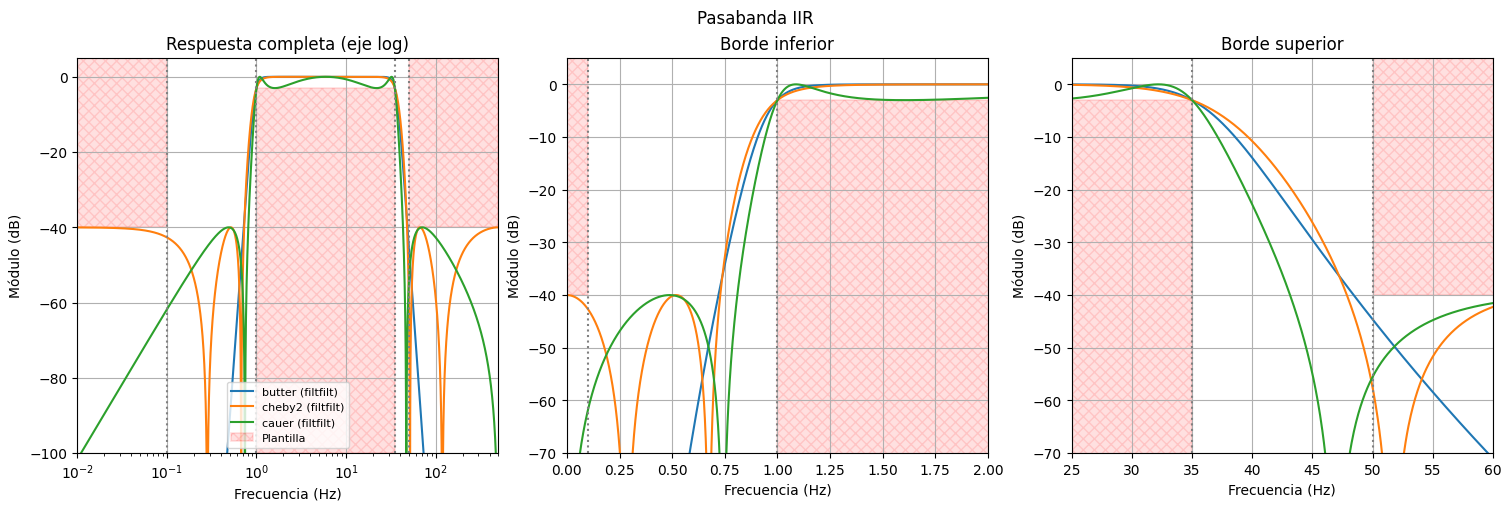

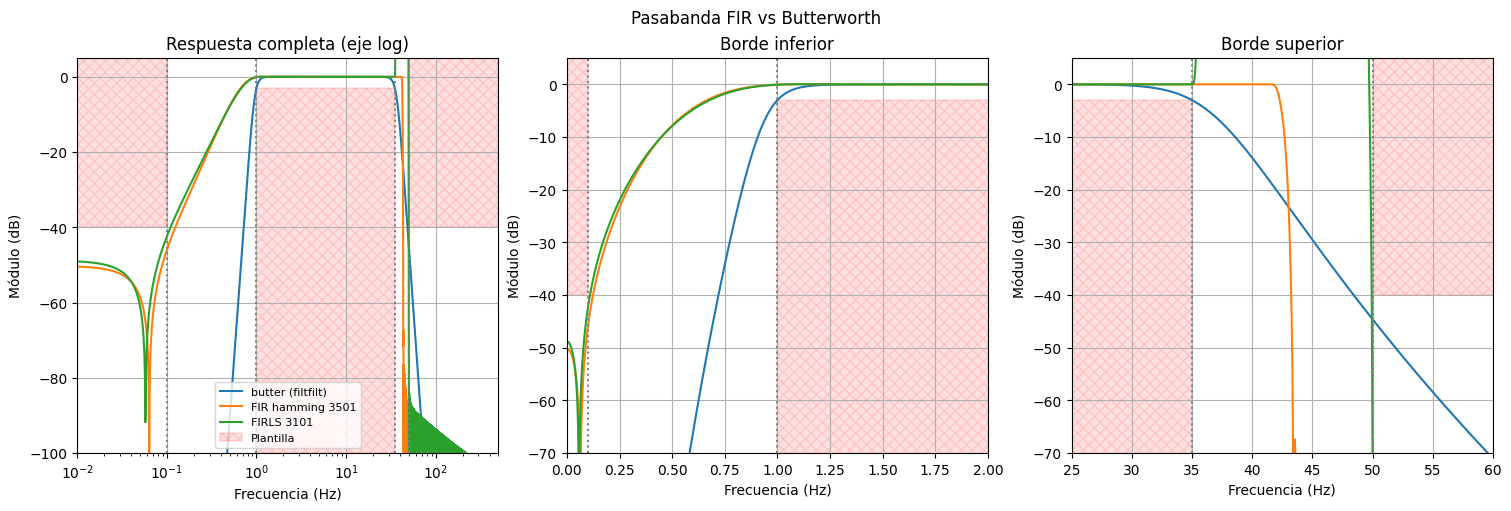

In [5]:
resp_iir = [(calc_freq_sos(sos_butt), 'butter (filtfilt)'),
            (calc_freq_sos(sos_cheby2), 'cheby2 (filtfilt)'),
            (calc_freq_sos(sos_cauer), 'cauer (filtfilt)')]

resp_fir = [(calc_freq_fir(b_win_hamming), f'FIR hamming {taps_win_hamm}'),
            (calc_freq_fir(b_firls), f'FIRLS {taps_firls}')]

graficar_filtros(resp_iir, 'Pasabanda IIR')
graficar_filtros([resp_iir[0]] + resp_fir, 'Pasabanda FIR vs Butterworth')

In [6]:
for (resp, nombre), sos in zip(resp_iir, (sos_butt, sos_cheby2, sos_cauer)):
    verificar(resp, nombre, f'orden {2 * sos.shape[0]}')
for (resp, nombre), b in zip(resp_fir, (b_win_hamming, b_firls)):
    verificar(resp, nombre, f'{len(b)} taps')

butter (filtfilt)      orden 16   min en paso =  -3.00 dB   max rechazo inf = -240.00 dB   max rechazo sup =  -44.60 dB   -> cumple
cheby2 (filtfilt)       orden 8   min en paso =  -3.00 dB   max rechazo inf =  -40.00 dB   max rechazo sup =  -40.00 dB   -> cumple
cauer (filtfilt)        orden 6   min en paso =  -3.00 dB   max rechazo inf =  -61.82 dB   max rechazo sup =  -40.00 dB   -> cumple
FIR hamming 3501      3501 taps   min en paso =  -0.06 dB   max rechazo inf =  -45.99 dB   max rechazo sup =  -90.74 dB   -> cumple
FIRLS 3101            3101 taps   min en paso =  -0.07 dB   max rechazo inf =  -42.40 dB   max rechazo sup =  -70.77 dB   -> cumple


## Aplicación al ECG

- IIR: `sosfiltfilt`.
- FIR: con miles de coeficientes, `lfilter` (que calcula la convolución directa) es muy lento sobre más de un millón de muestras. Uso `sig.oaconvolve` (convolución por bloques con FFT, *overlap-add*), que da el mismo resultado que `lfilter` si me quedo con las primeras $N$ muestras. Después compenso la demora $(N_{taps}-1)/2$.

In [7]:
ecg_filt_butt = sig.sosfiltfilt(sos_butt, ecg_one_lead)
ecg_filt_cheby2 = sig.sosfiltfilt(sos_cheby2, ecg_one_lead)
ecg_filt_cauer = sig.sosfiltfilt(sos_cauer, ecg_one_lead)

# equivalente a sig.lfilter(b, 1, ecg_one_lead), pero mucho más rápido
ecg_filt_winhamm = sig.oaconvolve(ecg_one_lead, b_win_hamming)[:N]
ecg_filt_firls = sig.oaconvolve(ecg_one_lead, b_firls)[:N]

demora_hamm = (taps_win_hamm - 1)//2
demora_firls = (taps_firls - 1)//2

cant_muestras = ecg_one_lead.shape[0]


def graficar_regiones( regs_interes ):

    for ii in regs_interes:

        # intervalo limitado de 0 a cant_muestras
        zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras - demora_hamm, ii[1]]), dtype='uint')

        plt.figure(figsize=(12, 5))
        plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
        plt.plot(zoom_region, ecg_filt_butt[zoom_region], label='Butter')
        plt.plot(zoom_region, ecg_filt_cheby2[zoom_region], label='Cheby2')
        plt.plot(zoom_region, ecg_filt_cauer[zoom_region], label='Cauer')
        plt.plot(zoom_region, ecg_filt_winhamm[zoom_region + demora_hamm], label='WinHam')
        plt.plot(zoom_region, ecg_filt_firls[zoom_region + demora_firls], label='FIRLS')

        plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
        plt.ylabel('Adimensional')
        plt.xlabel('Muestras (#)')

        axes_hdl = plt.gca()
        axes_hdl.legend()
        axes_hdl.set_yticks(())

        plt.show()

### Regiones de interés con ruido

Acá se ve el efecto del pasaaltos: el movimiento de línea de base desaparece y los latidos quedan centrados en cero.

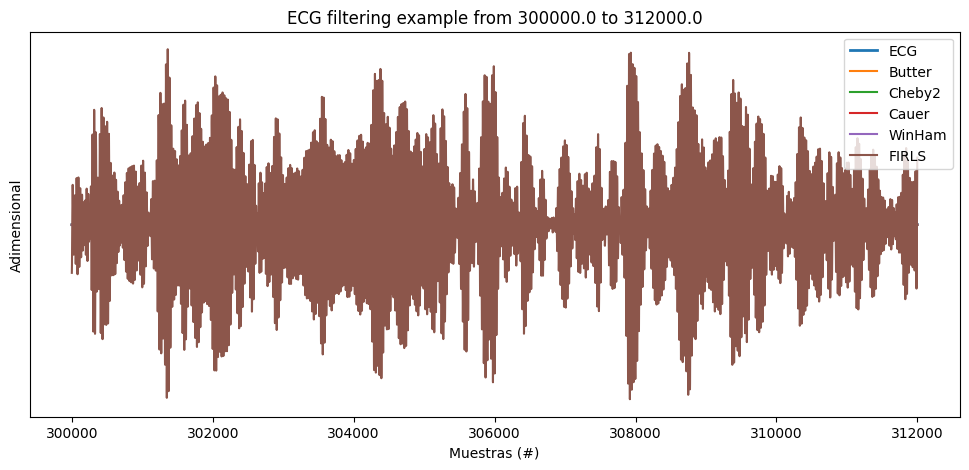

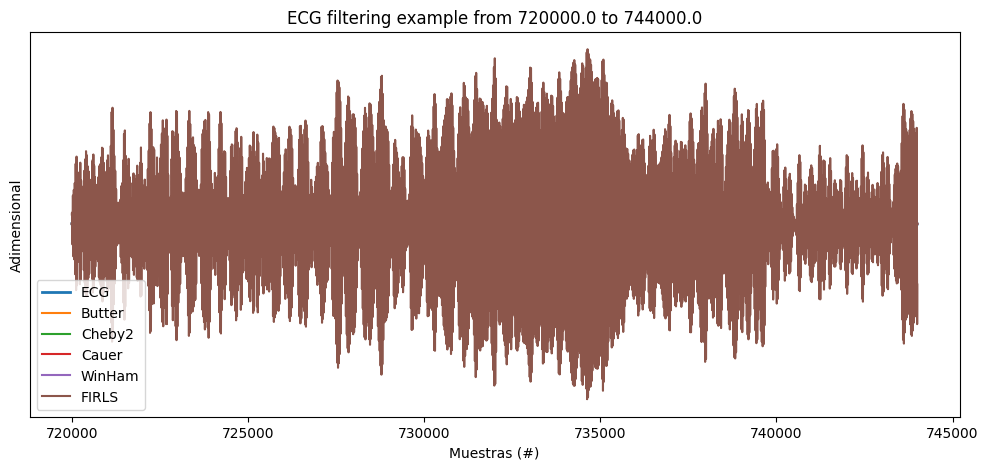

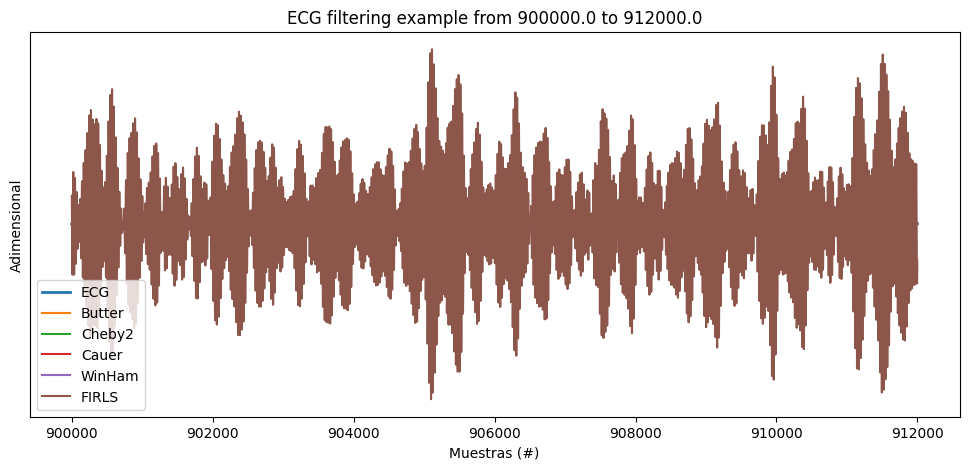

In [8]:
regs_interes = (
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecg, # minutos a muestras
        )

graficar_regiones(regs_interes)

### Regiones de interés sin ruido

En los latidos limpios hay que ver si el filtro **deforma** el ECG. Un pasaaltos con fase no lineal (IIR filtrado en un solo sentido) distorsiona sobre todo el segmento ST; con `filtfilt` o con FIR de fase lineal eso no pasa.

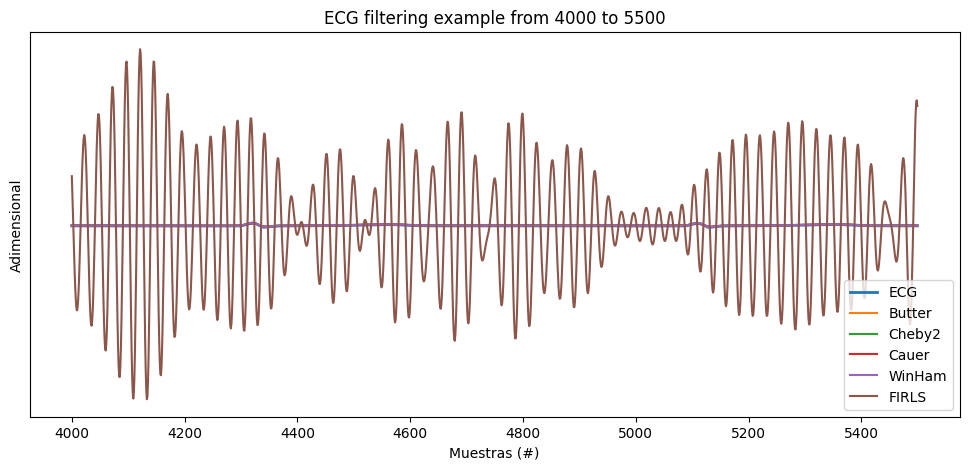

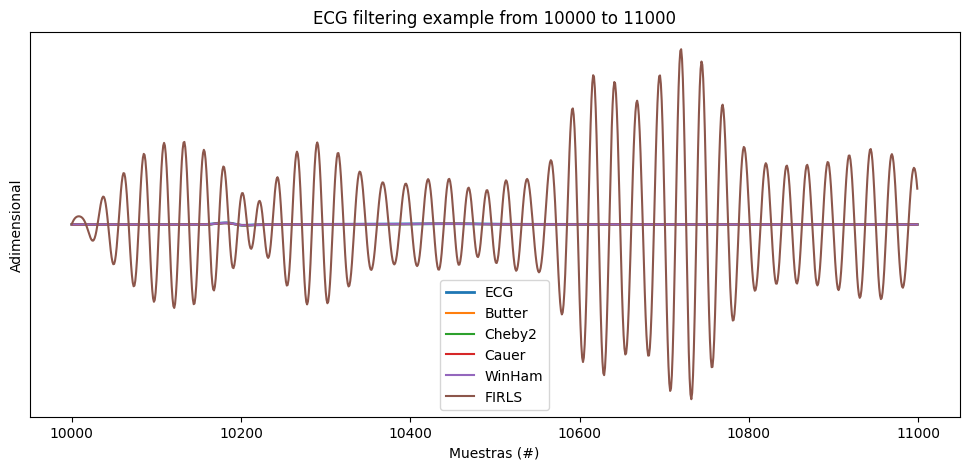

In [9]:
regs_interes = (
        [4000, 5500], # muestras
        [10000, 11000], # muestras
        )

graficar_regiones(regs_interes)

## Conclusiones

- **Los IIR resuelven el pasabanda con orden bajo:** Butterworth de orden 16, Chebyshev II de orden 8 y Cauer de orden 6. El orden del Butterworth lo impone la transición superior (35 a 50 Hz); por eso en el borde inferior le sobra atenuación (en 0.1 Hz cae más de 200 dB con `filtfilt`).
- **Los FIR necesitan miles de coeficientes:** 3501 con ventana Hamming y 3101 con cuadrados mínimos. La transición inferior de 0.9 Hz equivale a una resolución de ~1 s de señal, y el largo del FIR tiene que ser de ese orden: $N \approx 3.3\, f_s / \Delta f \approx 3700$ para Hamming. El borde superior queda sobrado (−70 a −90 dB).
- **Costo:** un FIR de 3500 coeficientes implica una **demora de 1.75 s** y ~3500 multiplicaciones por muestra, contra unas decenas en un IIR en SOS. Para aplicarlo hace falta la convolución por FFT (`oaconvolve`).
- **En el ECG**, el pasabanda elimina el movimiento de línea de base (los latidos quedan centrados en cero) además del ruido de alta frecuencia, que el pasabajos solo no podía sacar.
- Para un pasabanda con un borde inferior tan bajo, la opción práctica es un IIR con `filtfilt` (si se puede procesar fuera de línea), o separar el problema en un pasaaltos y un pasabajos, o usar técnicas de diezmado / FIR interpolados (ver el notebook de PyTC2 sobre *FIR recursivos e interpolados aplicados a ECG*).